<a href="https://colab.research.google.com/github/summerof69/Brier-Score/blob/main/notebooks/Brier_Score_Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Choosing a model with the Brier score: a practical walk-through

This notebook takes the **same BrightCart purchase propensity data and the same three models**
(logistic regression, random forest, LightGBM) from the Purchase Propensity Model series and asks one question:

> Brier Score help us o answer the question: **Can we trust each model's probabilities as numbers, and which model should we pick?**

ROC-AUC and lift tell us whether a model *ranks* customers well. They say nothing about whether a score of 0.30
really means a 30% chance of buying. The **Brier score** checks exactly that.

**What you will see**

 | Section | Step |
| --- | --- |
| 0-2 | Rebuild the dataset and train the three models (code copied unchanged from the series notebook) |
| 3 | Compute the Brier score by hand, then with scikit-learn |
| 4 | Compute the **baseline** Brier score: a "model" that always predicts the average purchase rate |
| 5 | Compare the three raw models against the baseline (Brier Skill Score) |
| 6 | Find out *why* they score the way they do: calibration vs refinement |
| 7 | Calibrate all three models and compare again |
| 8 | Pick the model |


## 0.Setup
- Install the libraries and write the two shared files, `config.py` and `utilspy`.

In [1]:
%pip install -q lightgbm shap pyarrow

import os, sys, warnings
import pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
os.makedirs("src", exist_ok=True)

RUN_WINDOW_EXPERIMENT = True     # about 4 minutes; set to False to skip section 11

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def show_img(name, width=820):
    display(Image(filename=f"images/{name}", width=width))

def show_csv(name, n=25):
    display(pd.read_csv(f"outputs/{name}").head(n))

### 0.1.Shared settings: `config.py`

In [3]:
%%writefile src/config.py
"""
Code Explanation:

- This is the central configuration for the Purchase Propensity Model (PPM) series and for the Brier Screo as well.

- Every script imports from here so that the observation window, prediction
window and split dates are defined in exactly ONE place.

"""
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Paths ----------
ROOT = Path(__file__).resolve().parents[1]
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "models"
OUT_DIR = ROOT / "outputs"
IMG_DIR = ROOT / "images"
for _d in (DATA_DIR, MODEL_DIR, OUT_DIR, IMG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ---------- Reproducibility ----------
SEED = 42

# ---------- Synthetic data settings (script 01) ----------
N_CUSTOMERS = 10_000
START_DATE = pd.Timestamp("2025-01-01")
N_DAYS = 210                     # Jan 1 -> Jul 29, 2025
CATEGORIES = ["Shoes", "Bags", "Electronics", "Fashion", "Home", "Beauty"]
PRODUCTS_PER_CATEGORY = 100

# ---------- Problem definition ----------
OBS_DAYS = 30                    # observation window: look back 30 days
PRED_DAYS = 7                    # prediction window: purchase in next 7 days
SESSION_GAP_MIN = 30             # inactivity threshold for sessionisation

#   Weekly scoring dates (Mondays). T0 = "prediction point".
#   Features use events with  T0 - OBS_DAYS <= timestamp < T0
#   Target   uses events with T0 <= timestamp < T0 + PRED_DAYS
FIRST_SNAPSHOT = pd.Timestamp("2025-02-03")
LAST_SNAPSHOT = pd.Timestamp("2025-07-21")
SNAPSHOT_DATES = pd.date_range(FIRST_SNAPSHOT, LAST_SNAPSHOT, freq="7D")

# ---------- Time-based split (by prediction point T0) ----------
# The label window of every training snapshot ends on or before the first
# validation T0, so no label information leaks across the boundary.
TRAIN_END = pd.Timestamp("2025-04-28")      # last T0 in train
VAL_START = pd.Timestamp("2025-05-05")
VAL_END = pd.Timestamp("2025-05-26")
TEST_START = pd.Timestamp("2025-06-02")

# ---------- Modelling ----------
TARGET = "target"
ID_COLS = ["customer_id", "snapshot_date"]
TOP_FRACTION = 0.10              # "top 10%" audience for lift / campaigns

# Columns kept in the dataset but NOT given to the model.
# tenure_days grows with the calendar, so it drifts by construction (PSI flags it immediately).
EXCLUDE_FEATURES = ["tenure_days"]


Overwriting src/config.py


### 0.2.Shared helpers: `utils.py`
Note the `PlattScaler` class near the bottom. We will use it in section 7 to calibrate the models.

In [5]:
%%writefile src/utils.py
"""
Code Explanation:
- Shared helpers used by scripts 04 to 11.

- Keeping these in one file means every script measures things the same way:
  the same train/validate/test split, the same definition of "lift", and so on.

"""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
import config as cfg


# ----------------------------------------------------------------------------
# Loading the data and splitting it by TIME (never randomly -- see Part 2)
# ----------------------------------------------------------------------------
def load_dataset() -> pd.DataFrame:
    return pd.read_parquet(cfg.DATA_DIR / "features.parquet")


def feature_columns(df: pd.DataFrame) -> list[str]:
    """
    - Every column except the ID columns, the target, and any feature we
    deliberately excluded (see config.EXCLUDE_FEATURES).
    """
    not_a_feature = cfg.ID_COLS + [cfg.TARGET] + cfg.EXCLUDE_FEATURES
    return [c for c in df.columns if c not in not_a_feature]


def time_split(df: pd.DataFrame):
    """
    - Split rows into train, validation and test by their prediction date,
    so the model is always tested on weeks it has never seen.
    """
    prediction_date = df["snapshot_date"]
    train = df[prediction_date <= cfg.TRAIN_END]
    validate = df[(prediction_date >= cfg.VAL_START) & (prediction_date <= cfg.VAL_END)]
    test = df[prediction_date >= cfg.TEST_START]
    return train, validate, test


# ----------------------------------------------------------------------------
# Ranking metrics: deciles, lift and cumulative gain
# ----------------------------------------------------------------------------
def decile_table(actual_outcome, predicted_score, n_bins: int = 10) -> pd.DataFrame:
    """
    - Rank customers from highest score to lowest, then cut them into
      `n_bins` equal-size groups (deciles). For each group, compare its real
      purchase rate to the overall purchase rate, that comparison is "lift".

    - A good model should show a much higher purchase rate in decile 1
      (highest scores) than in decile 10 (lowest scores).
    """
    ranked = pd.DataFrame({"bought": np.asarray(actual_outcome), "score": np.asarray(predicted_score)})
    ranked = ranked.sort_values("score", ascending=False).reset_index(drop=True)
    ranked["decile"] = (np.arange(len(ranked)) * n_bins // len(ranked)) + 1     # decile 1 = highest scores
    overall_rate = ranked["bought"].mean()

    table = ranked.groupby("decile").agg(customers=("bought", "size"), buyers=("bought", "sum"),
                                         purchase_rate=("bought", "mean")).reset_index()
    table["lift"] = table["purchase_rate"] / overall_rate
    table["cumulative_share_of_buyers"] = table["buyers"].cumsum() / ranked["bought"].sum()
    return table


def lift_at(actual_outcome, predicted_score, top_fraction: float = 0.10) -> float:
    """
    - How much better is the purchase rate in the TOP slice of scores,
      compared to the purchase rate across everyone?
    """
    ranked = pd.DataFrame({"bought": np.asarray(actual_outcome), "score": np.asarray(predicted_score)})
    ranked = ranked.sort_values("score", ascending=False)
    top_n = max(1, int(len(ranked) * top_fraction))
    return ranked["bought"].iloc[:top_n].mean() / ranked["bought"].mean()


def capture_at(actual_outcome, predicted_score, top_fraction: float = 0.10) -> float:
    """
    - Of ALL the customers who actually bought, what share were sitting
      in the top slice of the model's ranking?
    """
    ranked = pd.DataFrame({"bought": np.asarray(actual_outcome), "score": np.asarray(predicted_score)})
    ranked = ranked.sort_values("score", ascending=False)
    top_n = max(1, int(len(ranked) * top_fraction))
    return ranked["bought"].iloc[:top_n].sum() / ranked["bought"].sum()


def gain_curve(actual_outcome, predicted_score):
    """
    - Points for a cumulative gain chart: as we contact more and more
      customers (x, best score first), what share of all buyers have we
       reached so far (y)?
    """
    ranked = pd.DataFrame({"bought": np.asarray(actual_outcome), "score": np.asarray(predicted_score)})
    ranked = ranked.sort_values("score", ascending=False)
    share_contacted = np.arange(1, len(ranked) + 1) / len(ranked)
    share_of_buyers_found = ranked["bought"].cumsum().to_numpy() / ranked["bought"].sum()
    return np.r_[0, share_contacted], np.r_[0, share_of_buyers_found]


def evaluate(actual_outcome, predicted_score) -> dict:
    """
    - One dictionary with every metric we care about, so scripts can just
    call evaluate(...) once instead of computing each metric by hand.
    """
    p = np.clip(predicted_score, 0, 1)
    return {
        "roc_auc": roc_auc_score(actual_outcome, p),
        "pr_auc": average_precision_score(actual_outcome, p),
        "brier": brier_score_loss(actual_outcome, p),
        "lift_top10": lift_at(actual_outcome, p, 0.10),
        "capture_top10": capture_at(actual_outcome, p, 0.10),
        "mean_score": float(np.mean(p)),
        "base_rate": float(np.mean(actual_outcome)),
    }


# ----------------------------------------------------------------------------
# Calibration: turning a raw model score into a trustworthy probability
# ----------------------------------------------------------------------------
def _logit(p, eps: float = 1e-6):
    """
    - The logit is the inverse of a sigmoid: it turns a 0-to-1 probability
      back into an unbounded number, which is what Platt scaling needs.
    """
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


class PlattScaler:
    """
    - Platt scaling fixes an over- or under-confident model with one smooth
    S-curve. Internally it is nothing more than a logistic regression with
    a single input: the logit of the raw score.
    """

    def fit(self, raw_scores, actual_outcome) -> "PlattScaler":
        x = _logit(raw_scores).reshape(-1, 1)
        self.model = LogisticRegression(C=1e6, max_iter=1000).fit(x, actual_outcome)
        return self

    def predict(self, raw_scores):
        x = _logit(raw_scores).reshape(-1, 1)
        return self.model.predict_proba(x)[:, 1]


# ----------------------------------------------------------------------------
# A consistent look for every chart in the series
# ----------------------------------------------------------------------------
def set_plot_style():
    import matplotlib.pyplot as plt
    plt.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 150, "savefig.bbox": "tight",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
        "axes.titlesize": 12, "axes.titleweight": "bold",
    })
    return plt


BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2563eb", "#f59e0b", "#16a34a", "#dc2626", "#6b7280", "#7c3aed"


Overwriting src/utils.py


In [6]:
sys.path.insert(0, "src")
import config as cfg
print("Observation window:", cfg.OBS_DAYS, "days | Prediction window:", cfg.PRED_DAYS, "days")
print("Weekly prediction dates:", len(cfg.SNAPSHOT_DATES), "from", cfg.SNAPSHOT_DATES[0].date(), "to", cfg.SNAPSHOT_DATES[-1].date())

Observation window: 30 days | Prediction window: 7 days
Weekly prediction dates: 25 from 2025-02-03 to 2025-07-21


## 1.Rebuild the dataset
The next three cells are creatting the dataset:

1. Simulate a messy clickstream for 10,000 customers.
2. Clean it and group events into sessions.
3. Build one row per customer per Monday: features from the previous 30 days, target = *did they buy in the next 7 days?*

Because the random seed is fixed (`SEED = 42`), you get exactly the same data as in the series.

### 1a. Generate the clickstream

In [8]:
"""
01 - Create a pretend clickstream for the fictional retailer BrightCart.

The goal here is NOT to be clever. It is to produce data that behaves like real
customer behaviour, using code a data analyst can read top to bottom.

The story we simulate, in plain English:
    - Every customer has a hidden "chance of buying" called intent. We never
      show this number anywhere; it just controls how the customer behaves.
    - Most days, most customers do nothing.
    - Sometimes a customer starts a short "shopping episode" that lasts a
      few days. During an episode they browse more, and some episodes end
      in a purchase.
    - Outside of an episode, a customer still browses occasionally and can
      make a rare "impulse" purchase without any build-up.

Because Part 3 of the series is about CLEANING data, this file deliberately
saves a messy version at the end: duplicate rows, a few bot accounts, some
missing timestamps, and timestamps written in two different time zones.

Output files (written to data/):
    raw_events.parquet   - the messy clickstream, one row per event
    customers.csv        - one row per customer (signup date, consent, etc.)
"""

import numpy as np
import pandas as pd

import config as cfg

# The event types we simulate, listed in the order they normally happen
# during a single visit. Later code relies on this order.
EVENT_TYPES = ["login", "page_view", "search", "product_view", "wishlist",
               "add_to_cart", "remove_from_cart", "checkout", "purchase"]

TRAFFIC_SOURCES = ["organic", "paid_search", "social", "email", "direct"]
TRAFFIC_SOURCE_WEIGHTS = [0.35, 0.25, 0.15, 0.10, 0.15]

# No human generates this many events by hand in one day.
# We use this later to build a few fake "bot" accounts.
BOT_EVENTS_PER_ACCOUNT = 3000


# ============================================================================
# STEP 1: give every customer a few hidden traits.
# These never appear in the saved file. They only control how the customer
# behaves in the simulation below.
# ============================================================================
def make_customer_traits(rng: np.random.Generator) -> pd.DataFrame:
    n = cfg.N_CUSTOMERS
    return pd.DataFrame({
        "intent": rng.beta(1.2, 6.0, n),            # baseline chance of ever buying (mean ~17%)
        "browsing_level": rng.gamma(2.0, 0.5, n),    # how often this customer visits at all
        "favourite_category": rng.integers(0, len(cfg.CATEGORIES), n),
        "prefers_mobile": rng.beta(4, 3, n),         # 0 = always desktop, 1 = always mobile
    })


def pick_hour_of_day(rng: np.random.Generator, n: int) -> np.ndarray:
    """Shoppers browse more in the evening than early morning. This is just
    a weighted random pick from hour 0 to 23, with evening hours weighted higher."""
    weights = np.array([1, 1, 1, 1, 1, 2, 3, 4, 5, 5, 5, 5, 6, 5, 5, 5, 6, 7, 8, 10, 12, 12, 8, 4], dtype=float)
    return rng.choice(24, n, p=weights / weights.sum())


# ============================================================================
# STEP 2: simulate one single day for every customer.
# This is the heart of the file. It is one big function on purpose, so you
# can read it as a story: "here is what happens on day X".
# ============================================================================
def simulate_one_day(rng, traits, day_date, episode_days_left, will_buy_at_end) -> pd.DataFrame:
    """
    Returns a small DataFrame: one row per SESSION that happened today,
    with a count column for every event type (how many product views,
    how many cart adds, and so on, in that one session).

    `episode_days_left` and `will_buy_at_end` are numpy arrays, one entry
    per customer, that this function updates in place as episodes start
    and finish.
    """
    n_customers = len(traits)

    # --- 2a. Some customers who are not currently in an episode start one today.
    not_in_episode = episode_days_left == 0
    chance_of_starting_today = 0.004 + 0.02 * traits["intent"].to_numpy()
    starts_today = not_in_episode & (rng.random(n_customers) < chance_of_starting_today)

    n_new = int(starts_today.sum())
    episode_days_left[starts_today] = 2 + rng.poisson(4, n_new)          # episodes last 2 to ~10 days
    # the higher a customer's hidden intent, the more likely this episode ends in a sale
    will_buy_at_end[starts_today] = rng.random(n_new) < (0.25 + 0.60 * traits.loc[starts_today, "intent"].to_numpy())

    in_episode = episode_days_left > 0
    is_last_day_of_episode = episode_days_left == 1
    must_buy_today = is_last_day_of_episode & will_buy_at_end          # this customer WILL purchase today

    # --- 2b. Decide how many sessions (visits) each customer has today.
    # Customers currently in an episode browse much more than usual.
    expected_sessions = np.where(in_episode, 0.9 * np.sqrt(traits["browsing_level"]),
                                  0.05 * traits["browsing_level"])
    n_sessions = rng.poisson(expected_sessions)
    # A customer who must buy today is guaranteed at least one session.
    n_sessions = np.where(must_buy_today, np.maximum(n_sessions, 1), n_sessions)

    if n_sessions.sum() == 0:
        return pd.DataFrame(columns=["session_id", "customer_id", "session_start", "device",
                                      "traffic_source", "category", "product_id"] +
                                     [f"n_{e}" for e in EVENT_TYPES])

    # --- 2c. Build one row per session by repeating each customer by their session count.
    customer_row = np.repeat(np.arange(n_customers), n_sessions)
    session_in_episode = in_episode[customer_row]
    session_must_buy = must_buy_today[customer_row]
    n_today = len(customer_row)

    # --- 2d. Pick a device and traffic source for each session.
    is_mobile = rng.random(n_today) < traits["prefers_mobile"].to_numpy()[customer_row]
    device = np.where(is_mobile, "Mobile", np.where(rng.random(n_today) < 0.85, "Desktop", "Tablet"))
    traffic_source = rng.choice(TRAFFIC_SOURCES, n_today, p=TRAFFIC_SOURCE_WEIGHTS)

    # --- 2e. Pick what this session is "about": one category and one product.
    # A customer in an episode mostly looks at their favourite category.
    browses_favourite = rng.random(n_today) < np.where(session_in_episode, 0.85, 0.55)
    category_idx = np.where(browses_favourite, traits["favourite_category"].to_numpy()[customer_row],
                             rng.integers(0, len(cfg.CATEGORIES), n_today))
    category = np.array(cfg.CATEGORIES, dtype=object)[category_idx]
    product_id = "P" + pd.Series(category_idx * cfg.PRODUCTS_PER_CATEGORY
                                  + rng.integers(0, cfg.PRODUCTS_PER_CATEGORY, n_today) + 100).astype(str)

    # --- 2f. Decide how many of each event type happen in this session.
    # These are simple rules: more browsing and a higher chance of adding
    # to cart when the customer is in an episode, and guaranteed activity
    # on the day they are due to buy.
    n_page_view = 1 + rng.poisson(np.where(session_in_episode, 3.0, 1.0), n_today)
    n_search = rng.poisson(np.where(session_in_episode, 0.8, 0.3), n_today)
    n_login = (rng.random(n_today) < 0.5).astype(int)

    n_product_view = rng.poisson(np.where(session_in_episode, 5.0, 1.5), n_today)
    n_product_view = np.where(session_must_buy, np.maximum(n_product_view, 1), n_product_view)  # must look at something

    cart_add_chance = np.where(session_in_episode, 0.30, 0.05)
    n_add_to_cart = rng.binomial(n_product_view, cart_add_chance)
    n_add_to_cart = np.where(session_must_buy, np.maximum(n_add_to_cart, 1), n_add_to_cart)      # must have a cart

    n_remove_from_cart = rng.binomial(n_add_to_cart, 0.15)
    n_wishlist = rng.binomial(n_product_view, np.where(session_in_episode, 0.08, 0.03))

    checkout_chance = np.where(session_in_episode, 0.35, 0.10)
    checks_out = ((n_add_to_cart > 0) & (rng.random(n_today) < checkout_chance)) | session_must_buy
    n_checkout = checks_out.astype(int)

    # a customer NOT in an episode can still make a rare impulse purchase
    impulse_purchase = checks_out & ~session_in_episode & (rng.random(n_today) < 0.30)
    n_purchase = (session_must_buy | impulse_purchase).astype(int)

    hour = pick_hour_of_day(rng, n_today)
    session_start = day_date + pd.to_timedelta(hour * 3600 + rng.integers(0, 3600, n_today), unit="s")

    sessions_today = pd.DataFrame({
        "session_id": [f"C{c + 1:06d}_{day_date.strftime('%Y%m%d')}_{i}" for i, c in enumerate(customer_row)],
        "customer_id": "C" + pd.Series(customer_row + 1).astype(str).str.zfill(6),
        "session_start": session_start,
        "device": device, "traffic_source": traffic_source, "category": category, "product_id": product_id,
        "n_login": n_login, "n_page_view": n_page_view, "n_search": n_search,
        "n_product_view": n_product_view, "n_wishlist": n_wishlist, "n_add_to_cart": n_add_to_cart,
        "n_remove_from_cart": n_remove_from_cart, "n_checkout": n_checkout, "n_purchase": n_purchase,
    })

    # --- 2g. Close out episodes that just produced a purchase, and count down the rest.
    bought_today = np.zeros(n_customers, dtype=bool)
    bought_today[customer_row[n_purchase.astype(bool)]] = True
    episode_days_left[in_episode] -= 1
    episode_days_left[bought_today] = 0          # a purchase always ends the current episode early

    return sessions_today


# ============================================================================
# STEP 3: turn the session-level counts into one row per individual event.
# ============================================================================
def expand_sessions_into_events(sessions: pd.DataFrame, rng: np.random.Generator) -> pd.DataFrame:
    """
    `sessions` has one row per session with columns like n_product_view,
    n_add_to_cart, and so on. This function "unpacks" those counts into
    one row per event, in the natural order events happen (EVENT_TYPES).
    """
    HAS_PRODUCT = {"product_view", "wishlist", "add_to_cart", "remove_from_cart", "checkout", "purchase"}
    HAS_CATEGORY = HAS_PRODUCT | {"page_view"}

    parts = []
    for event in EVENT_TYPES:                              # keep the natural visit order
        count_col = f"n_{event}"
        rows_with_this_event = sessions[sessions[count_col] > 0]
        how_many = rows_with_this_event[count_col]
        # repeat each session row once per event of this type it contains
        expanded = rows_with_this_event.loc[rows_with_this_event.index.repeat(how_many)].copy()
        expanded["event"] = event
        if event not in HAS_PRODUCT:
            expanded["product_id"] = None
        if event not in HAS_CATEGORY:
            expanded["category"] = None
        parts.append(expanded[["session_id", "customer_id", "session_start", "device",
                                "traffic_source", "category", "product_id", "event"]])

    events = pd.concat(parts, ignore_index=True)

    # Space events out inside their session: a small random gap (10-90 seconds)
    # after the previous event of the SAME session. groupby().cumcount() counts
    # "how many rows of this session came before this one", using the order the
    # rows already appear in (which is the visit order, because we processed
    # EVENT_TYPES above in that order) -- no extra sorting needed.
    gap_seconds = rng.integers(10, 90, len(events))
    is_first_event_of_session = (events.groupby("session_id").cumcount() == 0).to_numpy()
    gap_seconds[is_first_event_of_session] = 0
    seconds_into_session = pd.Series(gap_seconds).groupby(events["session_id"].to_numpy()).cumsum()
    events["timestamp"] = events["session_start"] + pd.to_timedelta(seconds_into_session.to_numpy(), unit="s")
    return events.drop(columns="session_start")


# ============================================================================
# STEP 4: make the data dirty on purpose, so Part 3 has real cleaning to do.
# ============================================================================
def add_bot_traffic(events: pd.DataFrame, rng: np.random.Generator, n_bots: int = 25) -> pd.DataFrame:
    """A handful of fake accounts that fire thousands of page views in a
    row -- the kind of noise a tracking pixel or crawler leaves behind."""
    bot_rows = []
    for i in range(n_bots):
        start_time = cfg.START_DATE + pd.to_timedelta(
            rng.integers(0, cfg.N_DAYS * 86400 - 4000, 1)[0], unit="s")
        bot_rows.append(pd.DataFrame({
            "customer_id": f"BOT_{i:04d}",
            "timestamp": start_time + pd.to_timedelta(np.arange(BOT_EVENTS_PER_ACCOUNT), unit="s"),
            "event": "page_view", "product_id": None, "category": "Shoes",
            "device": "Desktop", "traffic_source": "direct",
        }))
    return pd.concat([events] + bot_rows, ignore_index=True)


def make_data_dirty(events: pd.DataFrame, rng: np.random.Generator) -> pd.DataFrame:
    events = add_bot_traffic(events, rng)

    # Duplicate about 1.5% of rows, as if a tracking tag fired twice.
    duplicate_rows = events.sample(frac=0.015, random_state=cfg.SEED)
    events = pd.concat([events, duplicate_rows], ignore_index=True)

    # Shuffle the file so it is NOT already sorted by customer or time,
    # which is how a real event log usually arrives.
    events = events.sample(frac=1.0, random_state=cfg.SEED).reset_index(drop=True)

    # Write 5% of timestamps in IST (UTC+5:30) and the rest in UTC, as
    # plain text -- exactly the kind of mixed time zone mess Part 3 fixes.
    logged_in_ist = rng.random(len(events)) < 0.05
    utc_text = events["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%S") + "Z"
    ist_text = (events["timestamp"] + pd.Timedelta(hours=5, minutes=30)).dt.strftime("%Y-%m-%dT%H:%M:%S") + "+05:30"
    events["timestamp"] = np.where(logged_in_ist, ist_text, utc_text)

    # A few timestamps go missing and a few customer IDs get corrupted,
    # both common in real logging pipelines.
    events.loc[rng.random(len(events)) < 0.003, "timestamp"] = None
    bad_id = rng.random(len(events)) < 0.003
    events.loc[bad_id, "customer_id"] = rng.choice(["", "UNKNOWN", "null"], bad_id.sum())

    return events[["customer_id", "timestamp", "event", "product_id", "category", "device", "traffic_source"]]


def make_customer_master(rng: np.random.Generator) -> pd.DataFrame:
    """A simple customer table: signup date, marketing consent, last time
    we contacted them. Used later for the campaign eligibility rules."""
    n = cfg.N_CUSTOMERS
    return pd.DataFrame({
        "customer_id": "C" + pd.Series(np.arange(1, n + 1)).astype(str).str.zfill(6),
        "signup_date": cfg.START_DATE - pd.to_timedelta(rng.integers(30, 900, n), unit="D"),
        "marketing_consent": (rng.random(n) < 0.85).astype(int),
        "last_contact_date": cfg.LAST_SNAPSHOT - pd.to_timedelta(rng.integers(0, 30, n), unit="D"),
    })


# ============================================================================
# MAIN: run the simulation day by day, then make the result dirty and save it.
# ============================================================================
if __name__ == "__main__":
    rng = np.random.default_rng(cfg.SEED)
    traits = make_customer_traits(rng)

    episode_days_left = np.zeros(cfg.N_CUSTOMERS, dtype=int)   # 0 means "not currently in an episode"
    will_buy_at_end = np.zeros(cfg.N_CUSTOMERS, dtype=bool)

    all_sessions = []
    for day_number in range(cfg.N_DAYS):
        day_date = cfg.START_DATE + pd.Timedelta(days=day_number)
        sessions_today = simulate_one_day(rng, traits, day_date, episode_days_left, will_buy_at_end)
        if len(sessions_today):
            all_sessions.append(sessions_today)

    sessions = pd.concat(all_sessions, ignore_index=True)
    print(f"Simulated sessions : {len(sessions):,}")

    clean_events = expand_sessions_into_events(sessions, rng)
    print(f"Simulated events   : {len(clean_events):,} (before we make the file messy)")

    dirty_events = make_data_dirty(clean_events, rng)
    dirty_events.to_parquet(cfg.DATA_DIR / "raw_events.parquet", index=False)
    make_customer_master(rng).to_csv(cfg.DATA_DIR / "customers.csv", index=False)

    print(f"Raw (messy) events : {len(dirty_events):,}")
    print(dirty_events["event"].value_counts().to_string())
    print(f"\nSaved to {cfg.DATA_DIR}")


Simulated sessions : 174,881
Simulated events   : 1,418,172 (before we make the file messy)
Raw (messy) events : 1,515,570
event
page_view           584680
product_view        536474
add_to_cart         124897
search               91860
login                89053
wishlist             35405
checkout             26911
remove_from_cart     18937
purchase              7353

Saved to /content/data


### 1b. Clean and build sessions

In [9]:
"""
02 - Clean the raw clickstream and group events into sessions.

We fix problems in this order, and the order matters:
    1. Drop rows with no timestamp or a broken customer ID -- nothing else
       can be trusted about a row we cannot place in time or attribute.
    2. Convert every timestamp to one single time zone (UTC) -- you must
       do this BEFORE removing duplicates, or the same event logged in two
       time zones looks like two different events.
    3. Drop duplicate events (the same customer, time, event and product).
    4. Drop bot traffic (accounts with an impossible number of events).
    5. Sort by customer and time.
    6. Group events into sessions using a "30 minutes of silence" rule.

Output files (written to data/):
    events_clean.parquet   - one row per valid event, with a session_id
    sessions.parquet       - one row per session, summarised

It also writes outputs/cleaning_report.csv, which records exactly how many
rows each step removed.
"""

import pandas as pd

import config as cfg

# No real person can generate more events than this in a single day.
# Any customer ID that does is almost certainly a bot or a tracking bug.
MAX_HUMAN_EVENTS_PER_DAY = 500


def drop_invalid_rows(events: pd.DataFrame) -> pd.DataFrame:
    """Remove rows with no timestamp, and rows whose customer ID does not
    match our expected pattern (a real customer or a known bot ID)."""
    events = events[events["timestamp"].notna()]
    looks_like_a_real_id = events["customer_id"].fillna("").str.match(r"^(C\d{6}|BOT_\d{4})$")
    return events[looks_like_a_real_id]


def standardise_timestamps(events: pd.DataFrame) -> pd.DataFrame:
    """Convert every timestamp string (some UTC, some IST) into one plain
    UTC timestamp column, so events can be compared and sorted directly."""
    as_utc = pd.to_datetime(events["timestamp"], utc=True, format="ISO8601")
    return events.assign(timestamp=as_utc.dt.tz_convert("UTC").dt.tz_localize(None))


def drop_duplicate_events(events: pd.DataFrame) -> pd.DataFrame:
    """Two rows with the same customer, time, event type and product are
    almost certainly the same click logged twice."""
    return events.drop_duplicates(subset=["customer_id", "timestamp", "event", "product_id"])


def find_bot_customer_ids(events: pd.DataFrame) -> pd.Index:
    """A simple rule: count events per customer per calendar day, and flag
    any customer who crosses the human-possible limit on any single day."""
    one_day = events["timestamp"].dt.date
    events_per_customer_per_day = events.groupby(["customer_id", one_day]).size()
    too_many = events_per_customer_per_day[events_per_customer_per_day > MAX_HUMAN_EVENTS_PER_DAY]
    return too_many.index.get_level_values("customer_id").unique()


def build_sessions(events: pd.DataFrame) -> pd.DataFrame:
    """
    Group each customer's events into sessions: a new session starts
    whenever more than 30 minutes pass with no activity.

    Step by step:
      1. For every event, look at how long ago that SAME customer's
         previous event was (`time_since_last_event`).
      2. If that gap is bigger than 30 minutes (or this is the customer's
         very first event), mark it as the start of a new session.
      3. Number the sessions for each customer in order (1, 2, 3, ...) by
         counting how many "new session" flags came before it.
    """
    time_since_last_event = events.groupby("customer_id")["timestamp"].diff()
    starts_new_session = time_since_last_event.isna() | (time_since_last_event > pd.Timedelta(minutes=cfg.SESSION_GAP_MIN))
    session_number = starts_new_session.groupby(events["customer_id"]).cumsum()

    events = events.copy()
    events["session_id"] = events["customer_id"] + "_" + session_number.astype(str).str.zfill(4)
    return events


def summarise_sessions(events_with_sessions: pd.DataFrame) -> pd.DataFrame:
    """Collapse the event-level table into one row per session: when it
    started and ended, how many events it had, and its device/source."""
    by_session = events_with_sessions.groupby("session_id", sort=False)
    sessions = by_session.agg(
        customer_id=("customer_id", "first"),
        session_start=("timestamp", "min"),
        session_end=("timestamp", "max"),
        n_events=("event", "size"),
        device=("device", "first"),
        traffic_source=("traffic_source", "first"),
    ).reset_index()
    sessions["duration_min"] = (sessions["session_end"] - sessions["session_start"]).dt.total_seconds() / 60
    return sessions


if __name__ == "__main__":
    raw_events = pd.read_parquet(cfg.DATA_DIR / "raw_events.parquet")
    row_counts = [("raw rows", len(raw_events))]

    events = drop_invalid_rows(raw_events)
    row_counts.append(("after dropping missing timestamps and bad customer IDs", len(events)))

    events = standardise_timestamps(events)          # must happen before de-duplication, see docstring

    events = drop_duplicate_events(events)
    row_counts.append(("after removing duplicate events", len(events)))

    bot_ids = find_bot_customer_ids(events)
    events = events[~events["customer_id"].isin(bot_ids)]
    row_counts.append((f"after removing bot traffic ({len(bot_ids)} bot IDs)", len(events)))

    events = events.sort_values(["customer_id", "timestamp"]).reset_index(drop=True)
    events = build_sessions(events)
    sessions = summarise_sessions(events)

    events.to_parquet(cfg.DATA_DIR / "events_clean.parquet", index=False)
    sessions.to_parquet(cfg.DATA_DIR / "sessions.parquet", index=False)

    report = pd.DataFrame(row_counts, columns=["step", "rows_remaining"])
    report["rows_removed"] = report["rows_remaining"].diff().fillna(0).abs().astype(int)
    report.to_csv(cfg.OUT_DIR / "cleaning_report.csv", index=False)

    print(report.to_string(index=False))
    print(f"\nSessions built: {len(sessions):,} (average {sessions['n_events'].mean():.1f} events per session)")


                                                  step  rows_remaining  rows_removed
                                              raw rows         1515570             0
after dropping missing timestamps and bad customer IDs         1506509          9061
                       after removing duplicate events         1484375         22134
               after removing bot traffic (25 bot IDs)         1409817         74558

Sessions built: 172,016 (average 8.2 events per session)


### 1c. Features and target

In [10]:
"""
03 - Build the modelling table: one row per (customer, prediction date).

For every weekly prediction date T0:
    FEATURES come ONLY from events before T0   (the observation window)
    TARGET   comes ONLY from events at or after T0, up to 7 days later
             (the prediction window)

Nothing at or after T0 is ever allowed into a feature. That single rule is
what stops the model from "cheating" by peeking at the future.

The features are grouped into small, clearly named functions, one per
"feature family" (see Part 3 of the blog series):
    A. Recency     B. Frequency     C. Engagement     D. Funnel
    E. Affinity    F. Device/channel     G. Time of week     H. Profile

Each function takes a slice of events or sessions and returns a small
table indexed by customer_id. main() joins all of them together and adds
the target column.

Output: data/features.parquet

"""

import numpy as np
import pandas as pd

import config as cfg

ONE_DAY = pd.Timedelta(days=1)


def days_since(last_seen: pd.Series, t0: pd.Timestamp, value_if_never_seen: float, customers: pd.Index) -> pd.Series:
    """How many days before t0 did this happen? If it never happened,
    use a large placeholder number instead of leaving it blank.
    `last_seen` only contains customers who DID the thing, so we first line it up
    with ALL active customers; the ones who never did it become blank and get the placeholder."""
    return ((t0 - last_seen.reindex(customers)) / ONE_DAY).clip(lower=0).fillna(value_if_never_seen)


# ----------------------------------------------------------------------------
# A. RECENCY: how recently did the customer do each kind of thing?
# ----------------------------------------------------------------------------
def recency_features(events: pd.DataFrame, sessions: pd.DataFrame, t0: pd.Timestamp, obs_days: int) -> pd.DataFrame:
    never_seen = obs_days + 1
    out = pd.DataFrame(index=pd.Index(sessions["customer_id"].unique(), name="customer_id"))
    out["days_since_last_visit"] = days_since(sessions.groupby("customer_id")["session_start"].max(), t0, never_seen, out.index)
    for label, event_name in [("product_view", "product_view"), ("cart_add", "add_to_cart"), ("checkout", "checkout")]:
        last_time = events.loc[events["event"] == event_name].groupby("customer_id")["timestamp"].max()
        out[f"days_since_last_{label}"] = days_since(last_time, t0, never_seen, out.index)
    last_purchase = events.loc[events["event"] == "purchase"].groupby("customer_id")["timestamp"].max()
    out["days_since_last_purchase"] = days_since(last_purchase, t0, never_seen, out.index)
    return out


# ----------------------------------------------------------------------------
# B. FREQUENCY: how often did the customer do each kind of thing?
# ----------------------------------------------------------------------------
def frequency_features(events: pd.DataFrame, events_last_7d: pd.DataFrame,
                       sessions: pd.DataFrame, sessions_last_7d: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=pd.Index(sessions["customer_id"].unique(), name="customer_id"))
    out["visits_30d"] = sessions.groupby("customer_id").size()
    out["visits_7d"] = sessions_last_7d.groupby("customer_id").size()

    event_column_name = {"product_view": "product_views", "add_to_cart": "add_to_carts", "search": "searches",
                          "wishlist": "wishlists", "checkout": "checkouts", "remove_from_cart": "remove_from_cart",
                          "purchase": "purchases"}
    counts_30d = events.groupby(["customer_id", "event"]).size().unstack(fill_value=0)
    counts_7d = events_last_7d.groupby(["customer_id", "event"]).size().unstack(fill_value=0)
    for event_name, column_name in event_column_name.items():
        out[f"{column_name}_30d"] = counts_30d.get(event_name)
        if event_name in ("product_view", "add_to_cart", "search", "wishlist", "checkout"):
            out[f"{column_name}_7d"] = counts_7d.get(event_name)
    return out


# ----------------------------------------------------------------------------
# C. ENGAGEMENT: how deep or focused was each visit?
# ----------------------------------------------------------------------------
def engagement_features(events: pd.DataFrame, sessions: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=pd.Index(sessions["customer_id"].unique(), name="customer_id"))
    by_customer = sessions.groupby("customer_id")
    out["avg_session_duration_min"] = by_customer["duration_min"].mean()
    out["events_per_session"] = by_customer["n_events"].mean()
    out["active_days_30d"] = events.groupby("customer_id")["timestamp"].apply(lambda ts: ts.dt.normalize().nunique())

    product_views = events[events["event"] == "product_view"]
    out["unique_products_viewed"] = product_views.groupby("customer_id")["product_id"].nunique()
    out["unique_categories_viewed"] = product_views.groupby("customer_id")["category"].nunique()
    return out


# ----------------------------------------------------------------------------
# D. FUNNEL: how far down visit -> view -> cart -> checkout did they get?
# These are simple ratios built from the frequency counts above.
# ----------------------------------------------------------------------------
def funnel_features(freq: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=freq.index)
    out["cart_rate_30d"] = freq["add_to_carts_30d"] / freq["product_views_30d"].replace(0, np.nan)
    out["cart_rate_7d"] = freq["add_to_carts_7d"] / freq["product_views_7d"].replace(0, np.nan)
    out["checkout_rate_30d"] = freq["checkouts_30d"] / freq["add_to_carts_30d"].replace(0, np.nan)
    # "is this week busier than the last month, on average?" -- a simple speeding-up signal
    out["view_momentum"] = freq["product_views_7d"] / (freq["product_views_30d"] + 1)
    return out


# ----------------------------------------------------------------------------
# E. AFFINITY: what does the customer seem interested in?
# ----------------------------------------------------------------------------
def affinity_features(events: pd.DataFrame) -> pd.DataFrame:
    product_views = events[events["event"] == "product_view"]
    out = pd.DataFrame(index=pd.Index(product_views["customer_id"].unique(), name="customer_id"))

    views_per_category = product_views.groupby(["customer_id", "category"]).size().unstack(fill_value=0)
    for category in cfg.CATEGORIES:
        out[f"views_in_{category.lower()}"] = views_per_category.get(category)
    out["top_category_share"] = views_per_category.max(axis=1) / views_per_category.sum(axis=1)

    views_per_product = product_views.groupby(["customer_id", "product_id"]).size()
    out["product_revisit_count"] = (views_per_product >= 2).groupby("customer_id").sum()
    out["max_views_same_product"] = views_per_product.groupby("customer_id").max()
    return out


# ----------------------------------------------------------------------------
# F. DEVICE AND CHANNEL: how does the customer usually shop?
# ----------------------------------------------------------------------------
def device_channel_features(sessions: pd.DataFrame) -> pd.DataFrame:
    device_share = pd.crosstab(sessions["customer_id"], sessions["device"], normalize="index")
    source_share = pd.crosstab(sessions["customer_id"], sessions["traffic_source"], normalize="index")
    out = pd.DataFrame(index=device_share.index)
    for device in ["Mobile", "Desktop", "Tablet"]:
        out[f"{device.lower()}_ratio"] = device_share.get(device)
    for source in ["organic", "paid_search", "social", "email", "direct"]:
        out[f"{source}_ratio"] = source_share.get(source)
    return out


# ----------------------------------------------------------------------------
# G. TIME OF WEEK: when does the customer usually shop?
# ----------------------------------------------------------------------------
def time_of_week_features(sessions: pd.DataFrame) -> pd.DataFrame:
    sessions = sessions.copy()
    hour = sessions["session_start"].dt.hour
    sessions["is_weekend"] = (sessions["session_start"].dt.dayofweek >= 5).astype(int)
    sessions["is_evening"] = hour.between(18, 23).astype(int)
    sessions["is_morning"] = hour.between(5, 11).astype(int)
    sessions["hour"] = hour

    by_customer = sessions.groupby("customer_id")
    out = pd.DataFrame(index=pd.Index(sessions["customer_id"].unique(), name="customer_id"))
    out["weekend_visit_ratio"] = by_customer["is_weekend"].mean()
    out["evening_visit_ratio"] = by_customer["is_evening"].mean()
    out["morning_visit_ratio"] = by_customer["is_morning"].mean()
    out["avg_hour_of_day"] = by_customer["hour"].mean()
    return out


# ----------------------------------------------------------------------------
# H. PROFILE: simple facts about the customer that do not come from events.
# Kept OUT of the model (see config.EXCLUDE_FEATURES) because tenure grows
# by one every day for every customer, so it drifts on its own over time.
# ----------------------------------------------------------------------------
def profile_features(customers: pd.DataFrame, t0: pd.Timestamp) -> pd.DataFrame:
    out = customers.set_index("customer_id")[["signup_date"]].copy()
    out["tenure_days"] = (t0 - out["signup_date"]).dt.days
    return out.drop(columns="signup_date")


# ----------------------------------------------------------------------------
# Put one prediction date together: features from before T0, target from after it.
# ----------------------------------------------------------------------------
def build_snapshot(events: pd.DataFrame, sessions: pd.DataFrame, customers: pd.DataFrame,
                   t0: pd.Timestamp, obs_days: int = cfg.OBS_DAYS) -> pd.DataFrame:
    window_start = t0 - obs_days * ONE_DAY
    last_7_days_start = t0 - 7 * ONE_DAY

    # Only events strictly BEFORE t0 are allowed into features.
    events_in_window = events[(events["timestamp"] >= window_start) & (events["timestamp"] < t0)]
    events_last_7d = events_in_window[events_in_window["timestamp"] >= last_7_days_start]
    sessions_in_window = sessions[(sessions["session_start"] >= window_start) & (sessions["session_start"] < t0)]
    sessions_last_7d = sessions_in_window[sessions_in_window["session_start"] >= last_7_days_start]

    # The modelling population is everyone who visited at least once in the
    # observation window. Some feature tables below cover a wider group
    # (profile_features knows every customer; affinity_features only knows
    # customers who viewed a product), so every table is reindexed onto this
    # exact population before joining -- otherwise a plain join would let the
    # widest table silently expand the population to everyone.
    population = pd.Index(sessions_in_window["customer_id"].unique(), name="customer_id")

    feature_tables = [
        recency_features(events_in_window, sessions_in_window, t0, obs_days),
        frequency_features(events_in_window, events_last_7d, sessions_in_window, sessions_last_7d),
        engagement_features(events_in_window, sessions_in_window),
        None,  # placeholder for funnel_features, filled in below once frequency is known
        affinity_features(events_in_window),
        device_channel_features(sessions_in_window),
        time_of_week_features(sessions_in_window),
        profile_features(customers, t0),
    ]
    feature_tables[3] = funnel_features(feature_tables[1])
    feature_tables = [table.reindex(population) for table in feature_tables]

    snapshot = pd.concat(feature_tables, axis=1)

    # Counts and ratios that are "not seen" should be zero, not blank.
    zero_when_missing = [c for c in snapshot.columns if any(key in c for key in
                         ["visits_", "_30d", "_7d", "views_in_", "unique_", "revisit", "max_views", "active_days"])]
    snapshot[zero_when_missing] = snapshot[zero_when_missing].fillna(0)
    snapshot = snapshot.fillna(0)

    # The target: did this customer purchase at or after T0, within the next 7 days?
    prediction_window_end = t0 + cfg.PRED_DAYS * ONE_DAY
    purchase_in_window = events.loc[(events["event"] == "purchase")
                                    & (events["timestamp"] >= t0)
                                    & (events["timestamp"] < prediction_window_end), "customer_id"].unique()
    snapshot[cfg.TARGET] = snapshot.index.isin(purchase_in_window).astype(int)

    snapshot.insert(0, "snapshot_date", t0)
    return snapshot.reset_index()


if __name__ == "__main__":
    events = pd.read_parquet(cfg.DATA_DIR / "events_clean.parquet")
    sessions = pd.read_parquet(cfg.DATA_DIR / "sessions.parquet")
    customers = pd.read_csv(cfg.DATA_DIR / "customers.csv", parse_dates=["signup_date"])

    all_snapshots = []
    for t0 in cfg.SNAPSHOT_DATES:
        snapshot = build_snapshot(events, sessions, customers, t0)
        all_snapshots.append(snapshot)
        print(f"{t0.date()}  rows={len(snapshot):>6,}  positives={snapshot[cfg.TARGET].sum():>4}  "
              f"rate={snapshot[cfg.TARGET].mean():.2%}")

    features = pd.concat(all_snapshots, ignore_index=True)
    features.to_parquet(cfg.DATA_DIR / "features.parquet", index=False)

    n_features = features.shape[1] - 3   # minus customer_id, snapshot_date, target
    print(f"\nDataset: {len(features):,} rows x {n_features} features | "
          f"overall purchase rate {features[cfg.TARGET].mean():.2%}")


2025-02-03  rows= 7,312  positives= 160  rate=2.19%
2025-02-10  rows= 7,349  positives= 129  rate=1.76%
2025-02-17  rows= 7,303  positives= 156  rate=2.14%
2025-02-24  rows= 7,379  positives= 142  rate=1.92%
2025-03-03  rows= 7,368  positives= 162  rate=2.20%
2025-03-10  rows= 7,320  positives= 168  rate=2.30%
2025-03-17  rows= 7,358  positives= 168  rate=2.28%
2025-03-24  rows= 7,400  positives= 188  rate=2.54%
2025-03-31  rows= 7,422  positives= 178  rate=2.40%
2025-04-07  rows= 7,454  positives= 186  rate=2.50%
2025-04-14  rows= 7,448  positives= 167  rate=2.24%
2025-04-21  rows= 7,415  positives= 147  rate=1.98%
2025-04-28  rows= 7,449  positives= 175  rate=2.35%
2025-05-05  rows= 7,450  positives= 151  rate=2.03%
2025-05-12  rows= 7,371  positives= 179  rate=2.43%
2025-05-19  rows= 7,340  positives= 182  rate=2.48%
2025-05-26  rows= 7,375  positives= 160  rate=2.17%
2025-06-02  rows= 7,372  positives= 171  rate=2.32%
2025-06-09  rows= 7,402  positives= 172  rate=2.32%
2025-06-16  

## 2.Train the three models

- The data is split **by time**: train on the oldest weeks, validate on the next block,
test on the newest weeks. The script saves every model's predicted probability for the validation and test rows.

- One detail matters a lot for this notebook: buyers are only about 2% of rows, so each model is trained with
**class weights** that make mistakes on buyers count for more. That helps the models notice buyers, but it also
pushes their probabilities **up**. Keep an eye on that in section 5.

train:  95,977 rows | 2025-02-03 -> 2025-04-28 | buyers 2.22%
val  :  29,536 rows | 2025-05-05 -> 2025-05-26 | buyers 2.28%
test :  59,175 rows | 2025-06-02 -> 2025-07-21 | buyers 2.38%

Validation results (base rate = 2.28%)
              model  roc_auc  pr_auc  brier  lift_top10  capture_top10  mean_score  base_rate
logistic_regression   0.8028  0.1852 0.1469      6.3257         0.6324      0.3501     0.0228
      random_forest   0.8050  0.2286 0.0879      6.6234         0.6622      0.2686     0.0228
           lightgbm   0.8034  0.2215 0.0285      6.6680         0.6667      0.0853     0.0228


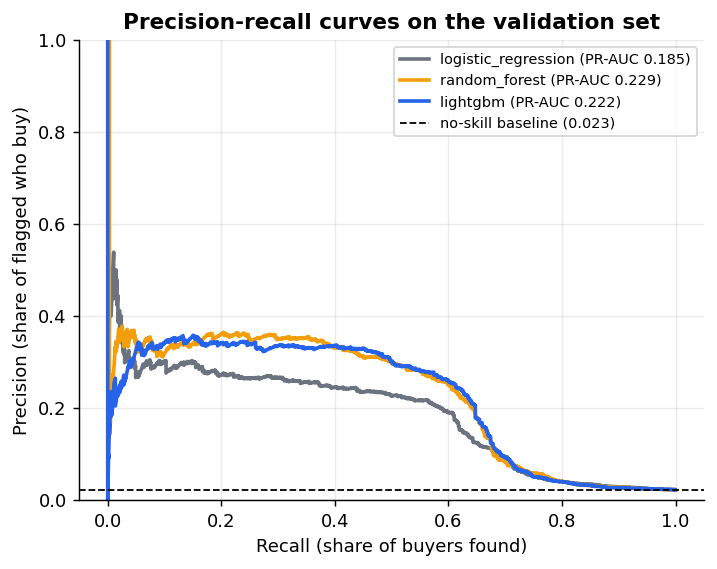

In [11]:
"""
 Train three models and compare them on a time-based split.

We train three models of increasing complexity, so we can see whether the
extra complexity actually buys us anything:
    1. Logistic regression - a simple, explainable baseline
    2. Random forest       - many decision trees, averaged together
    3. LightGBM            - gradient-boosted trees, usually the strongest
                             on tabular data like ours

The data is imbalanced (only about 2% of rows are buyers), so every model
is given "class weights": mistakes on a real buyer count for more than
mistakes on a non-buyer. This helps the model pay attention to the rare
class, but it also makes the raw scores over-confident, which is exactly
the problem Part 5 (calibration) fixes.

Outputs:
    models/*.joblib                      - the trained models and feature list
    outputs/model_comparison.csv         - validation metrics, side by side
    outputs/predictions_val.parquet      - every model's score on validation rows
    outputs/predictions_test.parquet     - every model's score on test rows
    images/ppm-05-model-comparison-pr-curves.png

"""

import joblib
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import config as cfg
import utils


def build_models(positive_class_weight: float) -> dict:
    """Return the three untrained models in a dictionary, so the rest of
    the script can just loop over them instead of repeating code three times."""
    return {
        "logistic_regression": make_pipeline(
            StandardScaler(),                              # logistic regression needs features on a similar scale
            LogisticRegression(C=0.3, max_iter=3000, class_weight="balanced")),
        "random_forest": RandomForestClassifier(
            n_estimators=200, max_depth=10, min_samples_leaf=30, max_features="sqrt",
            class_weight="balanced_subsample", n_jobs=-1, random_state=cfg.SEED),
        "lightgbm": lgb.LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=60,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
            scale_pos_weight=positive_class_weight, random_state=cfg.SEED, n_jobs=-1, verbose=-1),
    }


def train_and_score_one_model(name, model, X_train, y_train, X_val, X_test):
    """Fit one model, then return its predicted probabilities on the
    validation and test sets (we do not look at test metrics yet -- that
    happens in script 05, on the untouched test set)."""
    model.fit(X_train, y_train)
    val_scores = model.predict_proba(X_val)[:, 1]
    test_scores = model.predict_proba(X_test)[:, 1]
    joblib.dump(model, cfg.MODEL_DIR / f"{name}.joblib")
    return val_scores, test_scores


def plot_precision_recall_curves(results_by_model, y_val, path):
    """One chart with all three models' precision-recall curves, so it is
    easy to see which model trades precision for recall more gracefully."""
    plt = utils.set_plot_style()
    colors = {"logistic_regression": utils.GREY, "random_forest": utils.ORANGE, "lightgbm": utils.BLUE}

    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    for name, (val_scores, metrics) in results_by_model.items():
        precision, recall, _ = precision_recall_curve(y_val, val_scores)
        ax.plot(recall, precision, color=colors[name], lw=2, label=f"{name} (PR-AUC {metrics['pr_auc']:.3f})")
    ax.axhline(y_val.mean(), color="black", ls="--", lw=1, label=f"no-skill baseline ({y_val.mean():.3f})")
    ax.set(xlabel="Recall (share of buyers found)", ylabel="Precision (share of flagged who buy)",
           title="Precision-recall curves on the validation set", ylim=(0, 1))
    ax.legend(loc="upper right", fontsize=8)
    fig.savefig(path)


if __name__ == "__main__":
    data = utils.load_dataset()
    feature_names = utils.feature_columns(data)
    train, val, test = utils.time_split(data)

    for split_name, split_data in [("train", train), ("val", val), ("test", test)]:
        print(f"{split_name:5s}: {len(split_data):>7,} rows | "
              f"{split_data['snapshot_date'].min().date()} -> {split_data['snapshot_date'].max().date()} | "
              f"buyers {split_data[cfg.TARGET].mean():.2%}")

    X_train, y_train = train[feature_names], train[cfg.TARGET]
    X_val, y_val = val[feature_names], val[cfg.TARGET]
    X_test = test[feature_names]

    # A moderate class weight: the square root of the imbalance ratio.
    # Using the FULL ratio tends to overcorrect and hurt ranking quality.
    imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
    models = build_models(positive_class_weight=float(np.sqrt(imbalance_ratio)))

    results_by_model = {}
    val_predictions = val[cfg.ID_COLS + [cfg.TARGET]].copy()
    test_predictions = test[cfg.ID_COLS + [cfg.TARGET]].copy()

    for name, model in models.items():
        val_scores, test_scores = train_and_score_one_model(name, model, X_train, y_train, X_val, X_test)
        val_predictions[f"p_{name}"] = val_scores
        test_predictions[f"p_{name}"] = test_scores
        results_by_model[name] = (val_scores, utils.evaluate(y_val, val_scores))

    plot_precision_recall_curves(results_by_model, y_val, cfg.IMG_DIR / "ppm-05-model-comparison-pr-curves.png")

    comparison_table = pd.DataFrame(
        [{"model": name, **metrics} for name, (_, metrics) in results_by_model.items()]).round(4)
    comparison_table.to_csv(cfg.OUT_DIR / "model_comparison.csv", index=False)
    val_predictions.to_parquet(cfg.OUT_DIR / "predictions_val.parquet", index=False)
    test_predictions.to_parquet(cfg.OUT_DIR / "predictions_test.parquet", index=False)
    joblib.dump(feature_names, cfg.MODEL_DIR / "feature_list.joblib")

    print(f"\nValidation results (base rate = {y_val.mean():.2%})")
    print(comparison_table.to_string(index=False))


## 3.The Brier score

For each customer we take the predicted probability `p` and the real outcome `y` (1 = bought, 0 = did not buy),
square the difference, and average over everyone:

```text
Brier score = average of (p - y)²
```

- 0 is perfect. Lower is always better.
- A confident miss hurts a lot: predicting 0.9 for a non-buyer costs 0.81, predicting 0.1 costs only 0.01.

First, load the saved predictions and look at five real test customers.

In [12]:
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, roc_auc_score
import config as cfg
import utils

plt = utils.set_plot_style()
MODELS = ["logistic_regression", "random_forest", "lightgbm"]
COLORS = {"logistic_regression": utils.GREY, "random_forest": utils.ORANGE, "lightgbm": utils.BLUE}

val = pd.read_parquet(cfg.OUT_DIR / "predictions_val.parquet")
test = pd.read_parquet(cfg.OUT_DIR / "predictions_test.parquet")
y_val = val[cfg.TARGET].to_numpy()
y_test = test[cfg.TARGET].to_numpy()

# Five example customers from the test set: three who did not buy and two who did.
examples = pd.concat([
    test[test[cfg.TARGET] == 0].sample(3, random_state=7),
    test[test[cfg.TARGET] == 1].sample(2, random_state=7),
])[["customer_id", "p_lightgbm", cfg.TARGET]].rename(columns={"p_lightgbm": "predicted_p", cfg.TARGET: "bought"})
examples["squared_error"] = (examples["predicted_p"] - examples["bought"]) ** 2
display(examples.round(4).reset_index(drop=True))
print(f"Brier score for just these 5 customers: {examples['squared_error'].mean():.4f}")

,customer_id,predicted_p,bought,squared_error
0,C002886,0.0740,0,0.0055
1,C005404,0.0388,0,0.0015
2,C000954,0.0309,0,0.0010
3,C009997,0.0333,1,0.9344
4,C006607,0.6631,1,0.1135


Brier score for just these 5 customers: 0.2112


Now do the same over **all** test customers, once by hand with numpy and once with scikit-learn.
The two numbers must match. That is all `brier_score_loss` does.

In [13]:
for name in MODELS:
    p = test[f"p_{name}"].to_numpy()
    by_hand = np.mean((p - y_test) ** 2)
    sklearn_value = brier_score_loss(y_test, p)
    print(f"{name:20s}  by hand = {by_hand:.4f}   sklearn = {sklearn_value:.4f}")

logistic_regression   by hand = 0.1467   sklearn = 0.1467
random_forest         by hand = 0.0887   sklearn = 0.0887
lightgbm              by hand = 0.0294   sklearn = 0.0294


**What this tells us:** The three scores look small and close together. Is 0.03 good? You cannot tell
from the number alone, because the Brier score depends on how common the event is. You need something to compare it with.
That is the baseline.

## 4.The baseline Brier score

The simplest possible "model" ignores every feature and gives **every customer the same probability: the average
purchase rate**. Any model worth using must beat it.

We take the average from the **training** weeks, because in real life that is all you know when you score new customers.
For a constant prediction there is also a shortcut formula, `base_rate × (1 − base_rate)`, which gives almost the same value.

As a sanity check we also score the lazy "nobody ever buys" prediction (always 0).

In [14]:
data = utils.load_dataset()
train, _, _ = utils.time_split(data)
train_rate = train[cfg.TARGET].mean()
test_rate = y_test.mean()

baseline_brier = brier_score_loss(y_test, np.full(len(y_test), train_rate))
shortcut_formula = test_rate * (1 - test_rate)
always_zero_brier = brier_score_loss(y_test, np.zeros(len(y_test)))

print(f"Purchase rate in training weeks : {train_rate:.2%}")
print(f"Purchase rate in test weeks     : {test_rate:.2%}")
print()
print(f"Baseline Brier (always predict {train_rate:.2%}) : {baseline_brier:.4f}")
print(f"Shortcut formula {test_rate:.4f} x (1 - {test_rate:.4f})  : {shortcut_formula:.4f}")
print(f"'Nobody buys' (always predict 0)       : {always_zero_brier:.4f}")

Purchase rate in training weeks : 2.22%
Purchase rate in test weeks     : 2.38%

Baseline Brier (always predict 2.22%) : 0.0233
Shortcut formula 0.0238 x (1 - 0.0238)  : 0.0233
'Nobody buys' (always predict 0)       : 0.0238


**What this tells us:** a model that knows nothing about any customer already scores about **0.023**.
Even "nobody buys" scores about 0.024. With rare events every Brier score is small, so the only fair question is
**how much better than the baseline is the model?**

That comparison is the **Brier Skill Score (BSS)**:

```text
BSS = 1 − (model Brier / baseline Brier)
```

- BSS > 0: the model's probabilities are better than the baseline (1 would be perfect).
- BSS = 0: no better than predicting the average.
- BSS < 0: **worse than predicting the average**. Do not use these probabilities as numbers.

## 5.Compare the three raw models against the baseline

In [15]:
def brier_skill_score(brier):
    return 1 - brier / baseline_brier


rows = [{"model": "baseline (always predict train rate)", "brier": baseline_brier, "brier_skill_score": 0.0,
         "roc_auc": 0.5, "mean_predicted": train_rate}]
for name in MODELS:
    p = test[f"p_{name}"].to_numpy()
    brier = brier_score_loss(y_test, p)
    rows.append({"model": name, "brier": brier, "brier_skill_score": brier_skill_score(brier),
                 "roc_auc": roc_auc_score(y_test, p), "mean_predicted": p.mean()})

raw_table = pd.DataFrame(rows)
raw_table["beats_baseline"] = raw_table["brier"] < baseline_brier
raw_table.loc[0, "beats_baseline"] = None
print(f"Actual purchase rate in test weeks: {test_rate:.2%}")
display(raw_table.round(4))

Actual purchase rate in test weeks: 2.38%


,model,brier,brier_skill_score,roc_auc,mean_predicted,beats_baseline
0,baseline (always predict train rate),0.0233,0.0000,0.5000,0.0222,NaN
1,logistic_regression,0.1467,-5.3025,0.8020,0.3497,False
2,random_forest,0.0887,-2.8112,0.7918,0.2692,False
3,lightgbm,0.0294,-0.2651,0.8005,0.0857,False


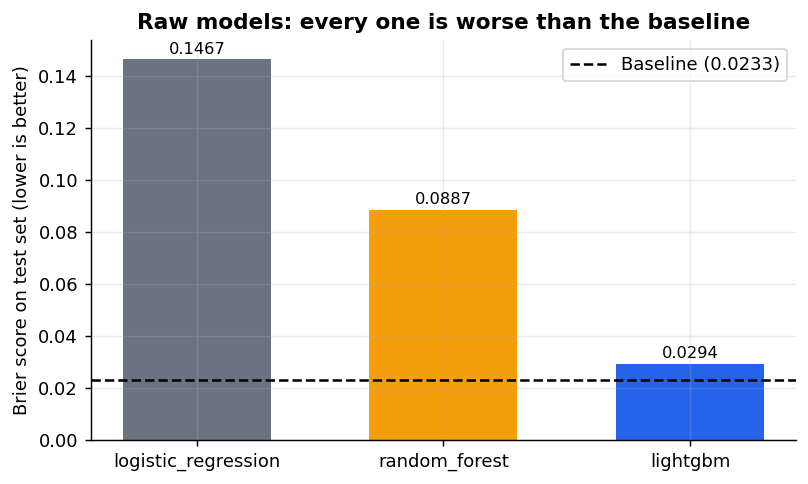

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
briers = raw_table.set_index("model").loc[MODELS, "brier"]
bars = ax.bar(MODELS, briers, color=[COLORS[m] for m in MODELS], width=0.6)
ax.axhline(baseline_brier, color="black", ls="--", lw=1.4, label=f"Baseline ({baseline_brier:.4f})")
for bar, value in zip(bars, briers):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.002, f"{value:.4f}", ha="center", fontsize=9)
ax.set(ylabel="Brier score on test set (lower is better)",
       title="Raw models: every one is worse than the baseline")
ax.legend()
plt.show()

**What this tells you**

- All three models rank customers about equally well (**ROC-AUC ≈ 0.80**). If you only looked at AUC, you could pick any of them.
- Yet **all three have a negative Brier Skill Score**. As probabilities, they are worse than saying "2.2%" to everyone.
- The `mean_predicted` column shows why: the models predict an average of 9% to 35% when the real rate is about 2.4%.
  The class weights from section 2 inflated their probabilities.
- Logistic regression is the worst offender, and LightGBM is the closest to the baseline.

So the models are good at **who** to contact and bad at **how likely** they are to buy.
The next section shows how to see that split directly.

## 6.Why: calibration vs refinement

The Brier score can be split into three parts (the *Murphy decomposition*):

```text
Brier ≈ calibration error − refinement + uncertainty
```

| Part | Meaning | Want it |
| --- | --- | --- |
| **Calibration error** (reliability) | Within groups of similar scores, how far is the average prediction from what actually happened? | Low |
| **Refinement** (resolution) | How well do the scores separate high-rate groups from low-rate groups? This is the ranking skill. | High |
| **Uncertainty** | `base_rate × (1 − base_rate)`. A property of the data, the same for every model. It equals the baseline Brier. | Fixed |

We group customers into 10 equal-size bins by predicted score to compute these.
The result is approximate because scores inside a bin are not all identical.

In [18]:
def brier_decomposition(actual_outcome, predicted_score, n_bins: int = 10) -> dict:
    """Split the Brier score into calibration error, refinement and uncertainty,
    using equal-size bins of predicted score."""
    df = pd.DataFrame({"y": actual_outcome, "p": predicted_score})
    df["bin"] = pd.qcut(df["p"].rank(method="first"), q=n_bins, labels=False)
    groups = df.groupby("bin").agg(n=("y", "size"), mean_p=("p", "mean"), observed=("y", "mean"))
    weight = groups["n"] / len(df)
    overall = df["y"].mean()
    return {
        "calibration_error": float((weight * (groups["mean_p"] - groups["observed"]) ** 2).sum()),
        "refinement": float((weight * (groups["observed"] - overall) ** 2).sum()),
        "uncertainty": overall * (1 - overall),
        "brier": brier_score_loss(actual_outcome, predicted_score),
    }


decomposition = pd.DataFrame(
    [{"model": name, **brier_decomposition(y_test, test[f"p_{name}"].to_numpy())} for name in MODELS])
display(decomposition.round(4))

,model,calibration_error,refinement,uncertainty,brier
0,logistic_regression,0.1255,0.0017,0.0233,0.1467
1,random_forest,0.0672,0.0018,0.0233,0.0887
2,lightgbm,0.0083,0.0018,0.0233,0.0294


**What this tells us:** compare the columns. Refinement (the ranking skill) is broadly similar across the three models, which matches their similar AUC.
The difference in Brier comes almost entirely from **calibration error**, which is large for logistic regression and
smallest for LightGBM. The reliability plot shows the same story: perfectly calibrated points would sit on the dashed line.

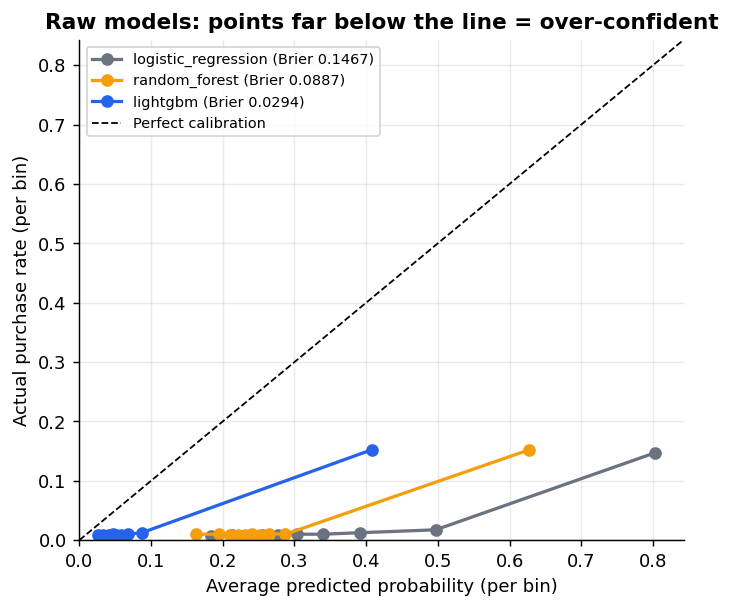

In [19]:
from sklearn.calibration import calibration_curve


def plot_reliability(scores_by_label, colors, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    highest = 0
    for label, score in scores_by_label.items():
        observed, predicted = calibration_curve(y_test, score, n_bins=10, strategy="quantile")
        brier = brier_score_loss(y_test, score)
        ax.plot(predicted, observed, marker="o", lw=1.8, color=colors[label], label=f"{label} (Brier {brier:.4f})")
        highest = max(highest, predicted.max(), observed.max())
    limit = highest * 1.05
    ax.plot([0, limit], [0, limit], color="black", ls="--", lw=1, label="Perfect calibration")
    ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Average predicted probability (per bin)",
           ylabel="Actual purchase rate (per bin)", title=title)
    ax.legend(fontsize=8, loc="upper left")
    plt.show()


plot_reliability({name: test[f"p_{name}"].to_numpy() for name in MODELS}, COLORS,
                 "Raw models: points far below the line = over-confident")

## 7.Fix the probabilities: calibrate all three models

Calibration reshapes a model's scores so they match real purchase rates, without retraining the model.
We try two standard methods, exactly as in the series notebook:

- **Platt scaling:** one smooth S-curve (the `PlattScaler` in `utils.py`).
- **Isotonic regression:** a flexible, step-shaped curve.

The golden rule: **fit the calibrator on the validation set, judge it on the test set.**
Platt scaling never changes the order of customers, so AUC and lift stay the same. Only the probabilities change.

In [20]:
from sklearn.isotonic import IsotonicRegression

test_scores = {}            # (model, version) -> calibrated test probabilities
rows = []
for name in MODELS:
    val_score, test_score = val[f"p_{name}"].to_numpy(), test[f"p_{name}"].to_numpy()
    platt = utils.PlattScaler().fit(val_score, y_val)
    isotonic = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(val_score, y_val)

    versions = {"raw": test_score, "platt": platt.predict(test_score), "isotonic": isotonic.predict(test_score)}
    for version, p in versions.items():
        test_scores[(name, version)] = p
        brier = brier_score_loss(y_test, p)
        rows.append({"model": name, "version": version, "brier": brier,
                     "brier_skill_score": brier_skill_score(brier), "roc_auc": roc_auc_score(y_test, p),
                     "mean_predicted": p.mean(), "beats_baseline": brier < baseline_brier})

results = pd.DataFrame(rows)
print(f"Baseline Brier: {baseline_brier:.4f}   |   actual purchase rate in test weeks: {test_rate:.2%}")
display(results.round(4))

Baseline Brier: 0.0233   |   actual purchase rate in test weeks: 2.38%


,model,version,brier,brier_skill_score,roc_auc,mean_predicted,beats_baseline
0,logistic_regression,raw,0.1467,-5.3025,0.8020,0.3497,False
1,logistic_regression,platt,0.0214,0.0819,0.8020,0.0229,True
2,logistic_regression,isotonic,0.0209,0.1005,0.7974,0.0228,True
3,random_forest,raw,0.0887,-2.8112,0.7918,0.2692,False
4,random_forest,platt,0.0201,0.1379,0.7918,0.0230,True
5,random_forest,isotonic,0.0199,0.1438,0.7934,0.0228,True
6,lightgbm,raw,0.0294,-0.2651,0.8005,0.0857,False
7,lightgbm,platt,0.0198,0.1499,0.8005,0.0229,True
8,lightgbm,isotonic,0.0198,0.1510,0.7973,0.0230,True


The same Brier Skill Scores as a model × version grid, which is easier to scan:

In [24]:
display(results.pivot(index="model", columns="version", values="brier_skill_score")
        .loc[MODELS, ["raw", "platt", "isotonic"]].round(3))

version,raw,platt,isotonic
model,,,
logistic_regression,-5.302,0.082,0.101
random_forest,-2.811,0.138,0.144
lightgbm,-0.265,0.150,0.151


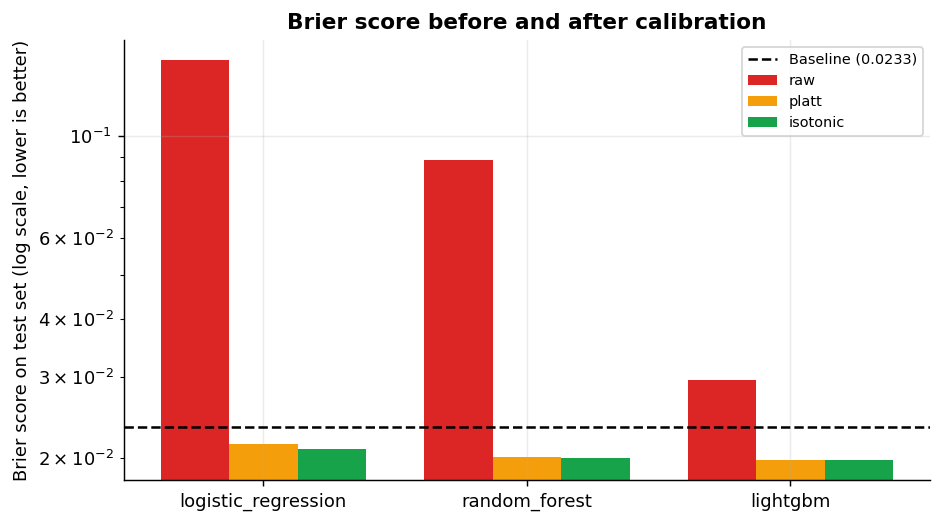

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.4))
width = 0.26
version_colors = {"raw": utils.RED, "platt": utils.ORANGE, "isotonic": utils.GREEN}
x = np.arange(len(MODELS))
for i, version in enumerate(["raw", "platt", "isotonic"]):
    values = [results.loc[(results["model"] == m) & (results["version"] == version), "brier"].iloc[0] for m in MODELS]
    ax.bar(x + (i - 1) * width, values, width, color=version_colors[version], label=version)
ax.axhline(baseline_brier, color="black", ls="--", lw=1.4, label=f"Baseline ({baseline_brier:.4f})")
ax.set_xticks(x, MODELS)
ax.set_yscale("log")
ax.set(ylabel="Brier score on test set (log scale, lower is better)",
       title="Brier score before and after calibration")
ax.legend(fontsize=8)
plt.show()

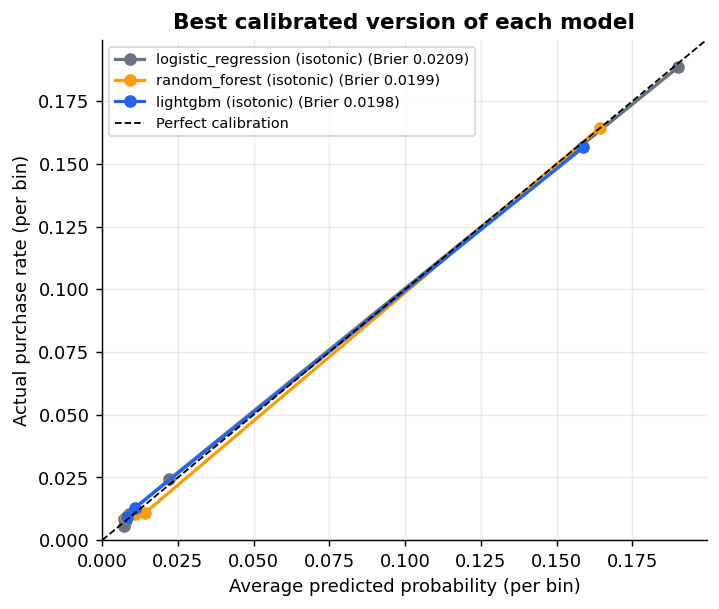

In [23]:
best_version = results.loc[results.groupby("model")["brier"].idxmin()].set_index("model")
plot_reliability({f"{m} ({best_version.loc[m, 'version']})": test_scores[(m, best_version.loc[m, "version"])]
                  for m in MODELS},
                 {f"{m} ({best_version.loc[m, 'version']})": COLORS[m] for m in MODELS},
                 "Best calibrated version of each model")

**What this tells you**

- Calibration pulls each model's average prediction close to the real purchase rate. Check the grid above: a calibrated
  version that drops below the dashed baseline line has a **positive** Brier Skill Score, and its probabilities can now be used as numbers.
- Platt scaling leaves AUC unchanged. Isotonic can shift it slightly because it merges similar scores into ties.
- Once calibration error is removed, the remaining differences between models come from **refinement**,
  their real ability to separate buyers from non-buyers.

## 8.Choose the model

The rule: among versions that **beat the baseline** (BSS > 0), pick the one with the **lowest test Brier score**.
Then check that its ranking (AUC) is still competitive.

In [ ]:
candidates = results[results["brier_skill_score"] > 0].sort_values("brier").reset_index(drop=True)
display(candidates.round(4))

winner = candidates.iloc[0]
runner_up = candidates[candidates["model"] != winner["model"]].iloc[0]
print(f"Chosen model : {winner['model']} + {winner['version']} calibration")
print(f"  Brier {winner['brier']:.4f} vs baseline {baseline_brier:.4f}  ->  "
      f"Brier Skill Score {winner['brier_skill_score']:.3f} "
      f"({winner['brier_skill_score']:.0%} better than predicting the average)")
print(f"  ROC-AUC {winner['roc_auc']:.3f} | mean predicted {winner['mean_predicted']:.2%} vs actual {test_rate:.2%}")
print(f"Best other model: {runner_up['model']} + {runner_up['version']} "
      f"(Brier {runner_up['brier']:.4f}, BSS {runner_up['brier_skill_score']:.3f})")

### How to read all of this

1. **Never read a Brier score on its own.** With a 2% event rate, every score is tiny. Always compute the baseline
   (`base_rate × (1 − base_rate)`) and report the **Brier Skill Score**.
2. **Good AUC does not mean good probabilities.** All three raw models had AUC ≈ 0.80 and still lost to the baseline.
3. **Class weights and oversampling inflate probabilities.** If you used them, calibrate on a held-out set before anyone
   uses the scores as numbers (budgets, expected revenue, thresholds like "contact if above 20%").
4. **Compare models after calibration.** Calibration is cheap, so the fair comparison is each model at its best.
   What is left is the model's real skill at separating buyers from non-buyers.
5. **If no model beats the baseline, use the scores only for ranking.** Their probabilities should not drive any decision.